# 📊 Notebook 01 — Exploratory Data Analysis (EDA)

## AI Customer Sentiment Analysis Dashboard

---

**Objective:** Comprehensive EDA on customer feedback to understand class distributions, text characteristics, and data quality.

**Outcomes:** Class distribution, text length analysis, word clouds, n-grams, time trends, noise detection, and train/val/test splits.

In [1]:
import os, re, html, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid', palette='viridis')
pd.set_option('display.max_colwidth', 120)
print('✅ All imports loaded successfully.')

✅ All imports loaded successfully.


## 2 · Generate Synthetic Customer Feedback Dataset

In [2]:
from faker import Faker
import random

fake = Faker(); Faker.seed(42); random.seed(42); np.random.seed(42)

POSITIVE_TEMPLATES = [
    'Absolutely love this product! {reason}. Will definitely buy again.',
    'Great customer service experience. {reason}. Highly recommend!',
    'Best purchase I made in a while. {reason}. Five stars!',
    'The quality exceeded my expectations. {reason}.',
    'Super fast shipping and the product works perfectly. {reason}.',
    'Fantastic value for the price. {reason}. Would recommend to anyone.',
    'Everything arrived on time and in great condition. {reason}.',
    'This is exactly what I needed! {reason}. Thank you so much.',
    'Amazing product, works like a charm. {reason}.',
    'Very pleased with my purchase. {reason}. Will order again.',
]

NEGATIVE_TEMPLATES = [
    'Terrible experience. {reason}. Will not buy from here again.',
    'The product broke after just one week. {reason}. Very disappointed.',
    'Customer support was unhelpful and rude. {reason}.',
    'Worst purchase ever. {reason}. Complete waste of money.',
    'The item arrived damaged and no one responded. {reason}.',
    'Very poor quality materials. {reason}. Feels cheap and flimsy.',
    'Misleading product description. {reason}. Not as advertised.',
    'Waited 3 weeks for delivery and still nothing. {reason}.',
    'The product stopped working after a few days. {reason}.',
    'Total scam. {reason}. I want my money back immediately.',
]

NEUTRAL_TEMPLATES = [
    'The product is okay. {reason}. Nothing special but decent.',
    'It works as described. {reason}. Average quality overall.',
    'Received the item on time. {reason}. Fine for the price.',
    'Not bad but not great either. {reason}. Mediocre experience.',
    'The product does its job. {reason}. Could be better though.',
    'Standard delivery and packaging. {reason}. Nothing to complain about.',
    'Meets expectations but does not exceed them. {reason}.',
    'Pretty standard experience overall. {reason}.',
    'Decent product for the price point. {reason}.',
    'Not impressed, not disappointed. {reason}. Just average.',
]

REASONS = [
    'The material feels premium', 'Shipping took longer than expected',
    'The color is exactly as shown', 'Easy to set up and use',
    'Instructions were unclear', 'Great for daily use',
    'Battery life could be better', 'The size is just right',
    'Packaging was very secure', 'It fits perfectly',
    'Customer service resolved my issue quickly', 'The warranty is generous',
    'Comfortable to use for long periods', 'The interface is intuitive',
    'Compatible with all my devices', 'Arrived in perfect condition',
]

SOURCES = ['website', 'app', 'email', 'social_media', 'support_ticket', 'survey']

In [3]:
def generate_feedback_dataset(n=5000):
    records = []
    label_weights = {'POSITIVE': 0.45, 'NEGATIVE': 0.30, 'NEUTRAL': 0.25}
    labels = np.random.choice(list(label_weights.keys()), size=n, p=list(label_weights.values()))
    template_map = {'POSITIVE': POSITIVE_TEMPLATES, 'NEGATIVE': NEGATIVE_TEMPLATES, 'NEUTRAL': NEUTRAL_TEMPLATES}
    for i, label in enumerate(labels):
        text = random.choice(template_map[label]).format(reason=random.choice(REASONS))
        if random.random() < 0.05: text = f'<p>{text}</p>'
        if random.random() < 0.03: text += f' Check out https://example.com/{fake.slug()}'
        records.append({'id': i, 'text': text, 'label': label, 'source': random.choice(SOURCES),
                        'customer_id': fake.uuid4()[:8], 'created_at': fake.date_time_between('-90d', 'now')})
    df = pd.DataFrame(records)
    df['created_at'] = pd.to_datetime(df['created_at'])
    return df.sort_values('created_at').reset_index(drop=True)

DATA_DIR = Path('../data'); DATA_DIR.mkdir(parents=True, exist_ok=True)
Path('../reports').mkdir(parents=True, exist_ok=True)
Path('../models').mkdir(parents=True, exist_ok=True)

df = generate_feedback_dataset(5000)
df.to_csv(DATA_DIR / 'customer_feedback.csv', index=False)
print(f'Dataset generated: {len(df):,} rows')
df.head(10)

Dataset generated: 5,000 rows


,id,text,label,source,customer_id,created_at
0,2008,Everything arrived on time and in great condition. Battery life could be better.,POSITIVE,email,cf51a203,2026-01-01 23:12:12
1,4121,Misleading product description. The material feels premium. Not as advertised.,NEGATIVE,app,dfe6b589,2026-01-01 23:20:56
2,4399,Very pleased with my purchase. Comfortable to use for long periods. Will order again.,POSITIVE,website,74cd173b,2026-01-01 23:55:39
3,1727,Meets expectations but does not exceed them. The size is just right.,NEUTRAL,social_media,743e8531,2026-01-02 00:27:03
4,4526,Terrible experience. Great for daily use. Will not buy from here again.,NEGATIVE,survey,a308f1ea,2026-01-02 00:27:19
5,290,"Amazing product, works like a charm. The color is exactly as shown.",POSITIVE,email,fcf56188,2026-01-02 01:27:20
6,140,"Not impressed, not disappointed. It fits perfectly. Just average.",NEUTRAL,email,6fa17735,2026-01-02 02:42:52
7,393,Standard delivery and packaging. Arrived in perfect condition. Nothing to complain about.,NEUTRAL,app,989240ac,2026-01-02 05:22:51
8,4954,Very poor quality materials. The interface is intuitive. Feels cheap and flimsy.,NEGATIVE,social_media,a210dd25,2026-01-02 05:53:18
9,2474,<p>Misleading product description. Compatible with all my devices. Not as advertised.</p>,NEGATIVE,survey,22d6f0a2,2026-01-02 05:56:27


## 3 · Dataset Overview

In [4]:
print(f'Shape: {df.shape}')
print(f'\nData Types:\n{df.dtypes}')
print(f'\nMissing Values:\n{df.isnull().sum()}')
print(f'\nDuplicate texts: {df["text"].duplicated().sum()}')
df.describe(include="all").T

Shape: (5000, 6)

Data Types:
id                      int64
text                   object
label                  object
source                 object
customer_id            object
created_at     datetime64[ns]
dtype: object

Missing Values:
id             0
text           0
label          0
source         0
customer_id    0
created_at     0
dtype: int64

Duplicate texts: 4174


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,5000.0,NaN,NaN,NaN,2499.5,0.0,1249.75,2499.5,3749.25,4999.0,1443.520003
text,5000,826,Absolutely love this product! Shipping took longer than expected. Will definitely buy again.,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,5000,3,POSITIVE,2277,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,5000,6,email,853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,5000,5000,cf51a203,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,5000,NaN,NaN,NaN,2026-02-15 10:31:36.370400,2026-01-01 23:12:12,2026-01-23 17:24:33.249999872,2026-02-15 02:29:45,2026-03-10 03:55:07.500000,2026-04-01 21:46:50,NaN


## 4 · Sentiment Class Distribution

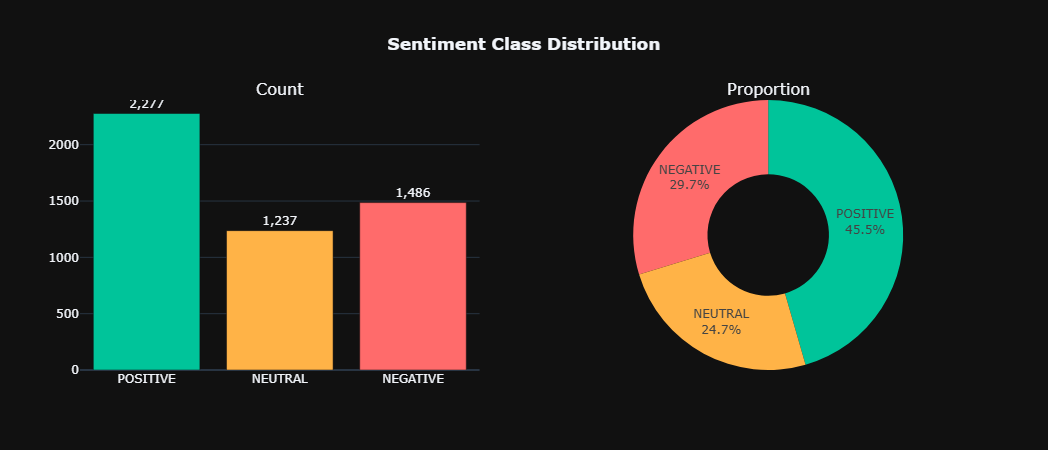

In [5]:
color_map = {'POSITIVE': '#00C49A', 'NEUTRAL': '#FFB347', 'NEGATIVE': '#FF6B6B'}
class_counts = df['label'].value_counts()

fig = make_subplots(rows=1, cols=2, specs=[[{'type':'bar'},{'type':'pie'}]],
                    subplot_titles=('Count','Proportion'))
for label in ['POSITIVE','NEUTRAL','NEGATIVE']:
    fig.add_trace(go.Bar(x=[label], y=[class_counts[label]], name=label,
                         marker_color=color_map[label], text=[f'{class_counts[label]:,}'],
                         textposition='outside'), row=1, col=1)
fig.add_trace(go.Pie(labels=class_counts.index.tolist(), values=class_counts.values.tolist(),
                     marker_colors=[color_map[l] for l in class_counts.index],
                     hole=0.45, textinfo='label+percent'), row=1, col=2)
fig.update_layout(title_text='<b>Sentiment Class Distribution</b>', title_x=0.5,
                  template='plotly_dark', height=450, showlegend=False)
fig.show()

## 5 · Text Length Analysis

         text_length                                            word_count  \
               count  mean   std   min   25%   50%   75%    max      count   
label                                                                        
NEGATIVE      1486.0  78.7  11.4  59.0  72.0  76.0  83.0  140.0     1486.0   
NEUTRAL       1237.0  77.1  12.5  54.0  70.0  76.0  82.0  145.0     1237.0   
POSITIVE      2277.0  78.8  12.1  55.0  72.0  78.0  84.0  148.0     2277.0   

                                                  
          mean  std  min   25%   50%   75%   max  
label                                             
NEGATIVE  12.4  1.5  9.0  11.0  12.0  13.0  18.0  
NEUTRAL   11.9  1.9  7.0  11.0  12.0  13.0  18.0  
POSITIVE  12.5  1.8  8.0  11.0  13.0  14.0  19.0  


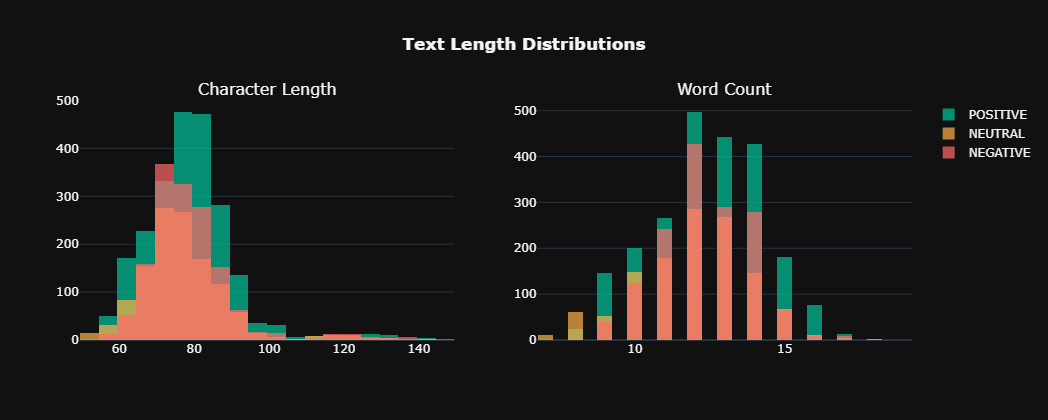

In [6]:
df['text_length'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()
print(df.groupby('label')[['text_length','word_count']].describe().round(1))

fig = make_subplots(rows=1, cols=2, subplot_titles=('Character Length','Word Count'))
for label in ['POSITIVE','NEUTRAL','NEGATIVE']:
    s = df[df['label']==label]
    fig.add_trace(go.Histogram(x=s['text_length'], name=label, marker_color=color_map[label],
                               opacity=0.7, nbinsx=40), row=1, col=1)
    fig.add_trace(go.Histogram(x=s['word_count'], name=label, marker_color=color_map[label],
                               opacity=0.7, nbinsx=30, showlegend=False), row=1, col=2)
fig.update_layout(title_text='<b>Text Length Distributions</b>', title_x=0.5,
                  template='plotly_dark', barmode='overlay', height=420)
fig.show()

## 6 · Word Clouds per Sentiment Class

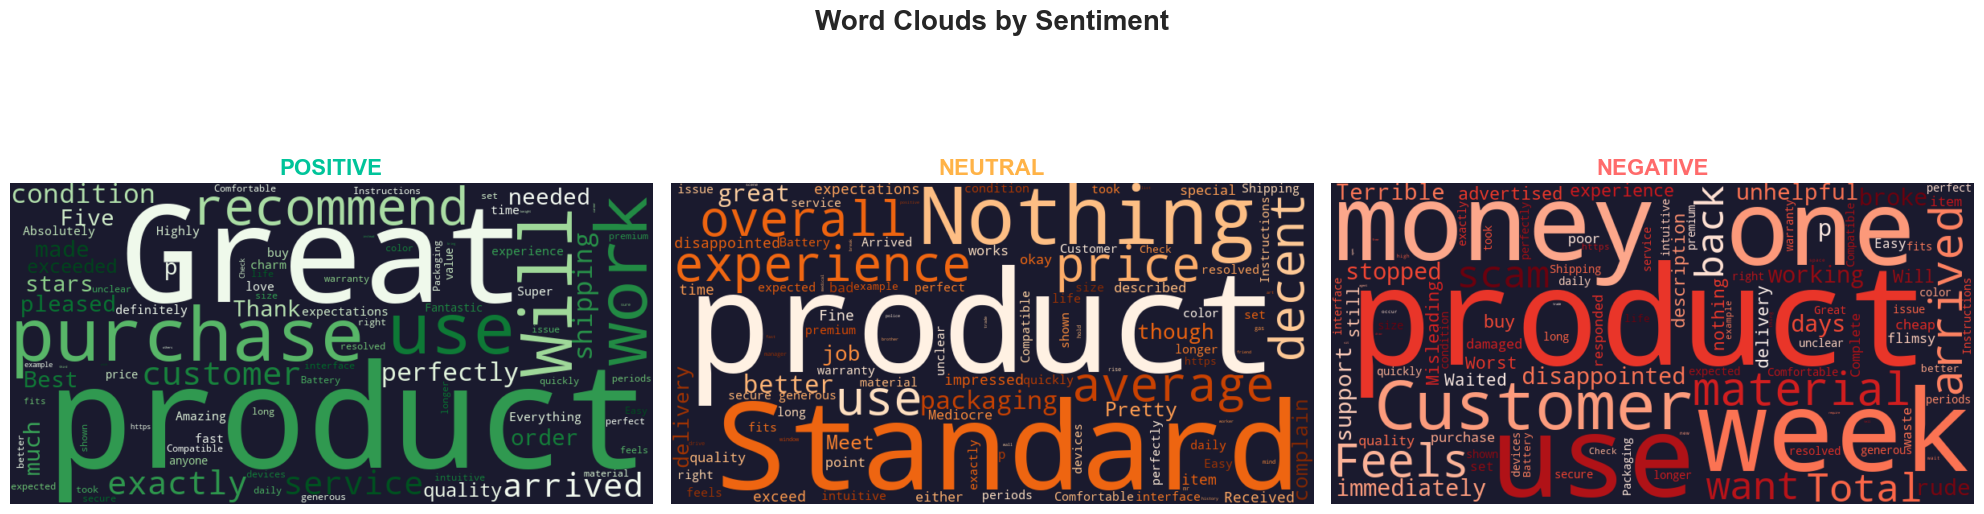

In [7]:
fig_wc, axes = plt.subplots(1, 3, figsize=(20, 6))
wc_cmaps = {'POSITIVE':'Greens','NEUTRAL':'Oranges','NEGATIVE':'Reds'}
for idx, label in enumerate(['POSITIVE','NEUTRAL','NEGATIVE']):
    corpus = ' '.join(df[df['label']==label]['text'].values)
    wc = WordCloud(width=800, height=400, background_color='#1a1a2e',
                   colormap=wc_cmaps[label], max_words=100, collocations=False).generate(corpus)
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(label, fontsize=16, fontweight='bold', color=color_map[label])
    axes[idx].axis('off')
fig_wc.suptitle('Word Clouds by Sentiment', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/wordclouds.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()

## 7 · Top Bigrams Analysis

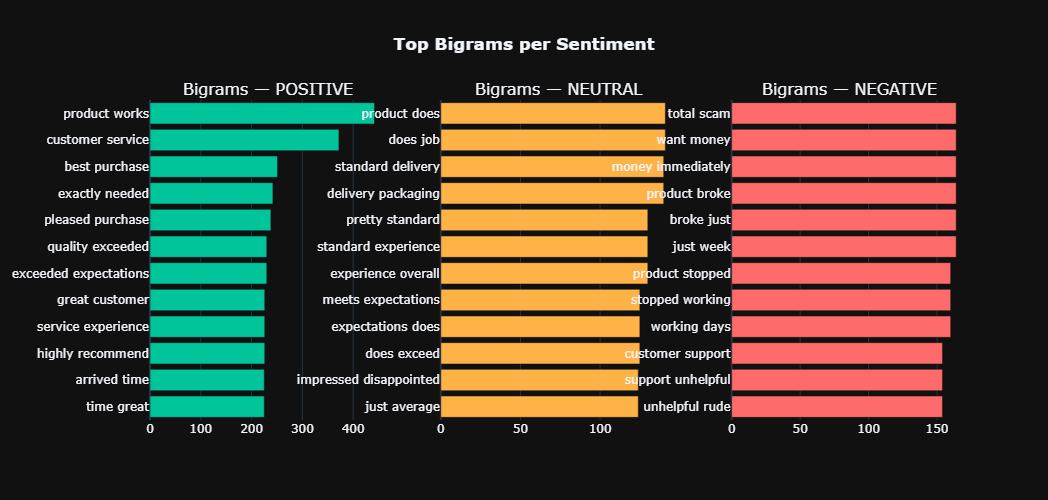

In [8]:
def get_top_ngrams(corpus, n=2, top_k=12):
    vec = CountVectorizer(ngram_range=(n,n), stop_words='english', max_features=5000)
    bag = vec.fit_transform(corpus)
    s = bag.sum(axis=0)
    words_freq = sorted([(w, int(s[0,i])) for w,i in vec.vocabulary_.items()],
                        key=lambda x: x[1], reverse=True)[:top_k]
    return pd.DataFrame(words_freq, columns=['ngram','count'])

fig = make_subplots(rows=1, cols=3, subplot_titles=[f'Bigrams — {l}' for l in ['POSITIVE','NEUTRAL','NEGATIVE']])
for idx, label in enumerate(['POSITIVE','NEUTRAL','NEGATIVE'], 1):
    ng = get_top_ngrams(df[df['label']==label]['text'], 2, 12)
    fig.add_trace(go.Bar(x=ng['count'], y=ng['ngram'], orientation='h',
                         name=label, marker_color=color_map[label]), row=1, col=idx)
fig.update_layout(title_text='<b>Top Bigrams per Sentiment</b>', title_x=0.5,
                  template='plotly_dark', height=500, showlegend=False)
fig.update_yaxes(autorange='reversed')
fig.show()

## 8 · Sentiment Over Time

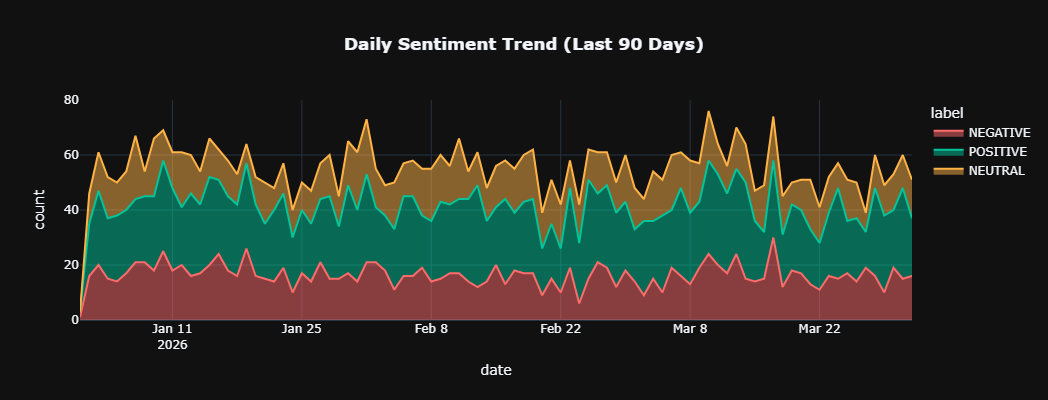

In [9]:
daily = df.groupby([df['created_at'].dt.date, 'label']).size().reset_index(name='count')
daily.columns = ['date','label','count']
fig = px.area(daily, x='date', y='count', color='label', color_discrete_map=color_map,
              title='<b>Daily Sentiment Trend (Last 90 Days)</b>', template='plotly_dark')
fig.update_layout(height=400, title_x=0.5)
fig.show()

## 9 · Source Channel Analysis

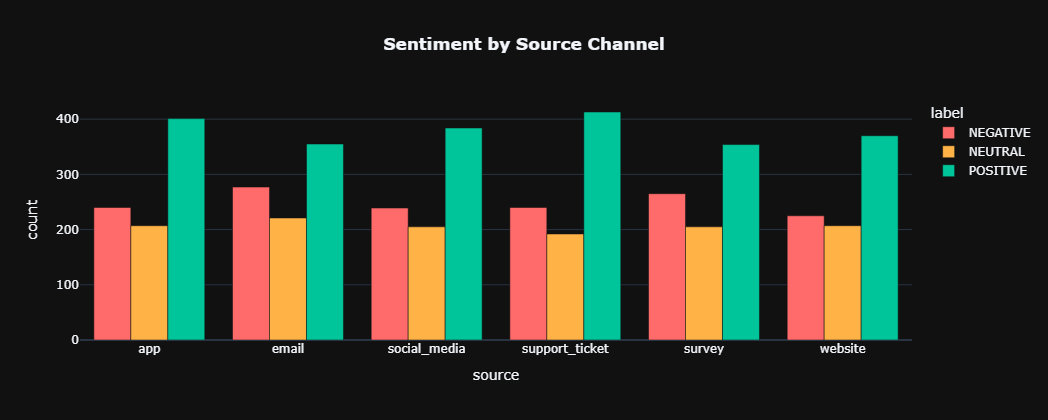

In [10]:
source_sent = df.groupby(['source','label']).size().reset_index(name='count')
fig = px.bar(source_sent, x='source', y='count', color='label', barmode='group',
             color_discrete_map=color_map, title='<b>Sentiment by Source Channel</b>',
             template='plotly_dark')
fig.update_layout(height=420, title_x=0.5)
fig.show()

## 10 · Noise Detection Report

In [11]:
df['has_html'] = df['text'].str.contains(r'<[^>]+>').astype(int)
df['has_url'] = df['text'].str.contains(r'https?://\S+').astype(int)
print('DATA QUALITY — NOISE DETECTION')
print(f"  HTML Tags: {df['has_html'].sum()} ({df['has_html'].mean()*100:.1f}%)")
print(f"  URLs:      {df['has_url'].sum()} ({df['has_url'].mean()*100:.1f}%)")
print('\n💡 These will be cleaned in notebook 02_preprocessing.')

DATA QUALITY — NOISE DETECTION
  HTML Tags: 251 (5.0%)
  URLs:      155 (3.1%)

💡 These will be cleaned in notebook 02_preprocessing.


## 11 · Train / Val / Test Split

In [12]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

train_df.to_csv(DATA_DIR / 'train.csv', index=False)
val_df.to_csv(DATA_DIR / 'val.csv', index=False)
test_df.to_csv(DATA_DIR / 'test.csv', index=False)

print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')
split_dist = pd.DataFrame({'Train%': train_df['label'].value_counts(normalize=True)*100,
                            'Val%': val_df['label'].value_counts(normalize=True)*100,
                            'Test%': test_df['label'].value_counts(normalize=True)*100})
print(split_dist.round(1))
print('\n✅ Notebook 01 Complete! Proceed to 02_preprocessing.ipynb')

Train: 3,500 | Val: 750 | Test: 750
          Train%  Val%  Test%
label                        
POSITIVE    45.5  45.6   45.5
NEGATIVE    29.7  29.7   29.7
NEUTRAL     24.7  24.7   24.8

✅ Notebook 01 Complete! Proceed to 02_preprocessing.ipynb
